# Variational Auto-Encoder Example

Build a variational auto-encoder (VAE) to generate digit images from a
noise distribution with JAX.

This example is using a low-level approach: the encoder and decoder are
plain Python functions, their weights are stored in a dictionary of arrays,
and the gradients are computed with `jax.grad`.

- Author: Aymeric Damien
- Project: [https://github.com/aymericdamien/JAX-Examples/](https://github.com/aymericdamien/JAX-Examples/)

## VAE Overview

<img src="http://kvfrans.com/content/images/2016/08/vae.jpg" alt="vae" style="width: 800px;"/>

References:
- [Auto-Encoding Variational Bayes The International Conference on Learning Representations](https://arxiv.org/abs/1312.6114) (ICLR), Banff, 2014. D.P. Kingma, M. Welling
- [Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification](https://arxiv.org/abs/1502.01852). K He, X Zhang, S Ren, J Sun. ICCV 2015.

Other tutorials:
- [Variational Auto Encoder Explained](http://kvfrans.com/variational-autoencoders-explained/). Kevin Frans.

## MNIST Dataset Overview

This example is using MNIST handwritten digits. The dataset contains 60,000 examples for training and 10,000 examples for testing. The digits have been size-normalized and centered in a fixed-size image (28x28 pixels) with values from 0 to 255.

In this example, each image will be converted to float32, normalized to [0, 1] and flattened to a 1-D array of 784 features (28*28).

![MNIST Dataset](http://neuralnetworksanddeeplearning.com/images/mnist_100_digits.png)

More info: http://yann.lecun.com/exdb/mnist/

In [1]:
import os
import sys

import jax
import jax.numpy as jnp
import numpy as np
import optax

# Make the shared helpers of the 'common' folder importable.
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from common.datasets import load_mnist, batch_iterator

In [2]:
# MNIST Dataset parameters.
image_dim = 784  # MNIST images are 28x28 pixels.

# Training parameters.
learning_rate = 0.001
training_steps = 30000
batch_size = 64
display_step = 1000

# Network parameters.
hidden_dim = 512
latent_dim = 2

In [3]:
# Prepare MNIST data.
(x_train, y_train), (x_test, y_test) = load_mnist()
# Convert to float32.
x_train, x_test = np.array(x_train, np.float32), np.array(x_test, np.float32)
# Flatten images to 1-D vector of 784 features (28*28).
x_train, x_test = x_train.reshape([-1, image_dim]), x_test.reshape([-1, image_dim])
# Normalize images value from [0, 255] to [0, 1].
x_train, x_test = x_train / 255., x_test / 255.

# Shuffle and batch data (a simple data loader, see 'common/datasets.py').
train_data = batch_iterator(x_train, y_train, batch_size)

In [4]:
# Store layers weight & bias.

# Random values are generated from a random 'key', which is split to get a
# new key for every use.
keys = jax.random.split(jax.random.key(0), 10)

# A custom initialization (see Kaiming He init): random values with a
# standard deviation of sqrt(2 / fan_in).
def he_init(key, shape):
    return jax.random.normal(key, shape) / jnp.sqrt(shape[0] / 2.)

# All the model parameters, gathered in a dictionary.
params = {
    'weights': {
        'encoder_h1': he_init(keys[0], [image_dim, hidden_dim]),
        'z_mean': he_init(keys[1], [hidden_dim, latent_dim]),
        'z_log_var': he_init(keys[2], [hidden_dim, latent_dim]),
        'decoder_h1': he_init(keys[3], [latent_dim, hidden_dim]),
        'decoder_out': he_init(keys[4], [hidden_dim, image_dim]),
    },
    'biases': {
        'encoder_b1': he_init(keys[5], [hidden_dim]),
        'z_mean': he_init(keys[6], [latent_dim]),
        'z_log_var': he_init(keys[7], [latent_dim]),
        'decoder_b1': he_init(keys[8], [hidden_dim]),
        'decoder_out': he_init(keys[9], [image_dim]),
    },
}

In [5]:
# Building the encoder.
# The encoder maps an image to a normal distribution in the latent space,
# described by its mean and its log-variance.
def encoder(params, x):
    weights, biases = params['weights'], params['biases']
    hidden_layer = jnp.matmul(x, weights['encoder_h1']) + biases['encoder_b1']
    hidden_layer = jnp.tanh(hidden_layer)
    z_mean = jnp.matmul(hidden_layer, weights['z_mean']) + biases['z_mean']
    z_log_var = jnp.matmul(hidden_layer, weights['z_log_var']) + biases['z_log_var']
    return z_mean, z_log_var

# Sampler: Normal (gaussian) random distribution.
# This is the 'reparameterization trick': the randomness comes from 'eps',
# so the gradients can flow through z_mean and z_log_var.
def sample_z(z_mean, z_log_var, key):
    eps = jax.random.normal(key, z_mean.shape)
    return z_mean + jnp.exp(z_log_var / 2) * eps

# Building the decoder.
# The decoder maps a point of the latent space back to an image.
def decoder(params, z):
    weights, biases = params['weights'], params['biases']
    hidden_layer = jnp.matmul(z, weights['decoder_h1']) + biases['decoder_b1']
    hidden_layer = jnp.tanh(hidden_layer)
    out_layer = jnp.matmul(hidden_layer, weights['decoder_out']) + biases['decoder_out']
    out_layer = jax.nn.sigmoid(out_layer)
    return out_layer

In [6]:
# Define VAE Loss.
def vae_loss(x_reconstructed, x_true, z_mean, z_log_var):
    # Reconstruction loss (binary cross-entropy, summed over the pixels).
    encode_decode_loss = x_true * jnp.log(1e-10 + x_reconstructed) \
                         + (1 - x_true) * jnp.log(1e-10 + 1 - x_reconstructed)
    encode_decode_loss = -jnp.sum(encode_decode_loss, 1)
    # KL Divergence loss (how far the encoded distribution is from N(0, 1)).
    kl_div_loss = 1 + z_log_var - jnp.square(z_mean) - jnp.exp(z_log_var)
    kl_div_loss = -0.5 * jnp.sum(kl_div_loss, 1)
    return jnp.mean(encode_decode_loss + kl_div_loss)

# RMSProp optimizer.
optimizer = optax.rmsprop(learning_rate)
# The optimizer state is stored outside of the optimizer.
opt_state = optimizer.init(params)

# Optimization process.
# @jax.jit compiles the function with XLA, so it runs much faster
# (see '1_Introduction/transformations.py').
@jax.jit
def run_optimization(params, opt_state, x, key):
    # Define the loss as a function of the parameters, to differentiate it.
    def loss_fn(params):
        z_mean, z_log_var = encoder(params, x)
        z = sample_z(z_mean, z_log_var, key)
        x_reconstructed = decoder(params, z)
        return vae_loss(x_reconstructed, x, z_mean, z_log_var)

    # Compute the loss and its gradients with respect to every parameter.
    loss, gradients = jax.value_and_grad(loss_fn)(params)

    # Update W and b following gradients.
    updates, opt_state = optimizer.update(gradients, opt_state)
    params = optax.apply_updates(params, updates)

    # JAX arrays can't be modified in place: return the updated values.
    return params, opt_state, loss

In [7]:
# Run training for the given number of steps.
key = jax.random.key(1)
for step in range(1, training_steps + 1):
    # Get the next batch of data (only the images are needed, not the labels).
    batch_x, _ = next(train_data)
    # Get a new random key for this step's sampling noise.
    key, sample_key = jax.random.split(key)
    # Run the optimization.
    params, opt_state, loss = run_optimization(params, opt_state, batch_x, sample_key)

    if step % display_step == 0 or step == 1:
        print("step: %i, loss: %f" % (step, loss))

step: 1, loss: 655.080200


step: 1000, loss: 173.896210


step: 2000, loss: 162.790390


step: 3000, loss: 169.916351


step: 4000, loss: 166.235168


step: 5000, loss: 170.584137


... (21 outputs left out)

step: 27000, loss: 146.063690


step: 28000, loss: 150.614441


step: 29000, loss: 159.853180


step: 30000, loss: 149.810333


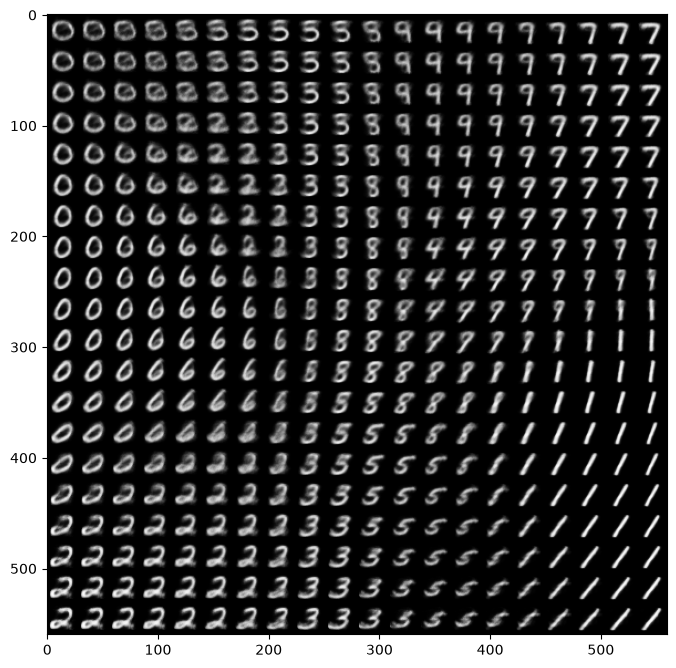

In [8]:
# Testing and Visualization.
import matplotlib.pyplot as plt

# Building a manifold of generated digits.
# The decoder alone is a generator: it turns any point of the 2-D latent
# space into an image. We decode a regular grid of latent points.
n = 20
x_axis = np.linspace(-3, 3, n)
y_axis = np.linspace(-3, 3, n)
z_grid = np.array([[xi, yi] for yi in y_axis for xi in x_axis], np.float32)
# Generate all the images at once, and reshape them to (row, column, 28, 28).
x_generated = np.asarray(decoder(params, z_grid)).reshape([n, n, 28, 28])

canvas = np.empty((28 * n, 28 * n))
for i in range(n):
    for j in range(n):
        # Draw the generated digits (the highest 'y' value on top).
        canvas[(n - i - 1) * 28:(n - i) * 28, j * 28:(j + 1) * 28] = x_generated[i, j]

plt.figure(figsize=(8, 10))
plt.imshow(canvas, origin="upper", cmap="gray")
plt.show()